# 03 · Exploratory Data Analysis
*EV capacity planning for PowerCharge Utilities · notebook 3 of 8 · Anna Tafri*

Reads: `data/processed/ev_events_clean.csv` (output of Notebook 02)  
Writes: `reports/figures/03_*.png`, `reports/eda_segment_tests.csv`

### Business questions
EDA is only useful if it is aimed at a decision. Every section here answers a question that feeds the capacity assessment:

1. When does EV charging load happen, and how concentrated is it in the evening peak?
2. Who and what drives consumption? Area, customer type, EV type, charger type, or charging habit?
3. Does weather move demand?
4. Where is load concentrated across substations?

### A note on rigour
With 97 events, small differences between groups can easily be noise. So every segment comparison comes with a statistical test (Kruskal–Wallis, which does not assume normality) and 95% confidence intervals. A finding is only called a finding if it survives that test.


## 0. Setup and chart style

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = PROJECT_ROOT / "data" / "processed"
REPORTS = PROJECT_ROOT / "reports"
FIGURES = REPORTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", "{:,.2f}".format)

# One consistent, accessible chart style for the whole project
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.edgecolor": GRID, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")

KWH = "electricity_consumption_kwh"
df = pd.read_csv(PROCESSED / "ev_events_clean.csv", parse_dates=["timestamp"])
print(df.shape)

(97, 30)


## 1. Headline numbers
Before any chart: what is the size of the problem we are looking at?

In [2]:
peak = df["is_peak_hour"]
kpis = pd.Series({
    "Charging events": len(df),
    "Total energy (kWh)": df[KWH].sum(),
    "EVs represented": df["number_of_evs"].sum(),
    "Substations with EV load": df["substation_id"].nunique(),
    "Avg energy per event (kWh)": df[KWH].mean(),
    "Days covered": (df["timestamp"].max() - df["timestamp"].min()).days,
    "Share of energy in 17:00-21:00 peak": df.loc[peak, KWH].sum() / df[KWH].sum(),
})
kpis.to_frame("value").style.format("{:,.0f}").format("{:.1%}", subset=pd.IndexSlice[["Share of energy in 17:00-21:00 peak"], :])

,value
Charging events,97
Total energy (kWh),"49,678"
EVs represented,509
Substations with EV load,49
Avg energy per event (kWh),512
Days covered,38
Share of energy in 17:00-21:00 peak,24.5%


## 2. Distribution of consumption
What does a 'typical' event look like, and are there outliers that could distort averages?

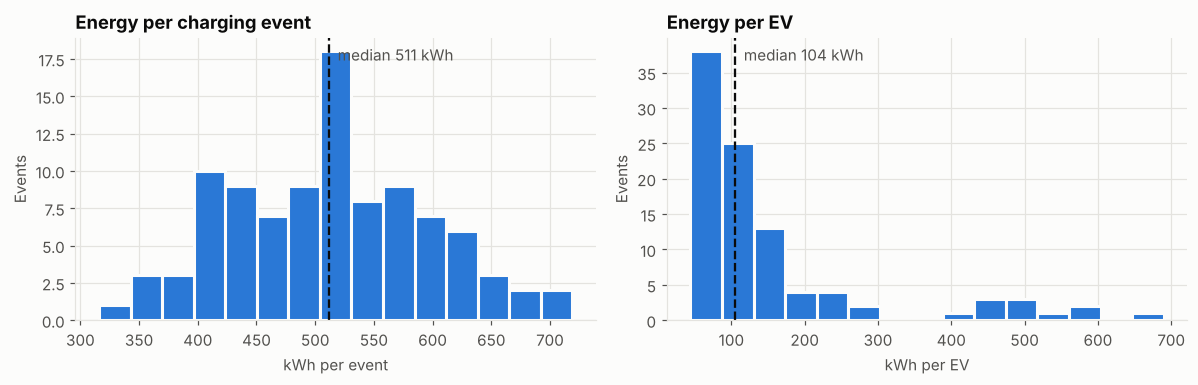

Skewness: 0.15 | IQR outliers: 0


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

ax = axes[0]
ax.hist(df[KWH], bins=15, color=BLUE, edgecolor=SURFACE, linewidth=2)
ax.axvline(df[KWH].median(), color=INK, linewidth=1.5, linestyle="--")
ax.annotate(f"median {df[KWH].median():,.0f} kWh", xy=(df[KWH].median(), ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=INK_2)
ax.set(title="Energy per charging event", xlabel="kWh per event", ylabel="Events")

ax = axes[1]
ax.hist(df["kwh_per_ev"], bins=15, color=BLUE, edgecolor=SURFACE, linewidth=2)
ax.axvline(df["kwh_per_ev"].median(), color=INK, linewidth=1.5, linestyle="--")
ax.annotate(f"median {df['kwh_per_ev'].median():,.0f} kWh", xy=(df["kwh_per_ev"].median(), ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=INK_2)
ax.set(title="Energy per EV", xlabel="kWh per EV", ylabel="Events")

fig.tight_layout(); save(fig, "03_01_distribution"); plt.show()

q1, q3 = df[KWH].quantile([.25, .75]); iqr = q3 - q1
outliers = df[(df[KWH] < q1 - 1.5 * iqr) | (df[KWH] > q3 + 1.5 * iqr)]
print(f"Skewness: {df[KWH].skew():.2f} | IQR outliers: {len(outliers)}")

**Reading it**
- Energy per event is tightly packed, roughly symmetric around ~510 kWh with no IQR outliers. Averages are safe to use here.
- Energy per EV is strongly right-skewed (from ~44 to ~690 kWh). It is driven by how many EVs share a site, not by the energy itself.
- ⚠️ Data caveat: `number_of_evs` has no relationship with total kWh (see section 6). A site with 9 EVs uses the same energy as a site with 1. In this dataset, consumption behaves like a site-level measure, so we plan capacity on site energy, not per-vehicle energy.

## 3. When does load happen?
### 3a. Hour of day: the evening peak

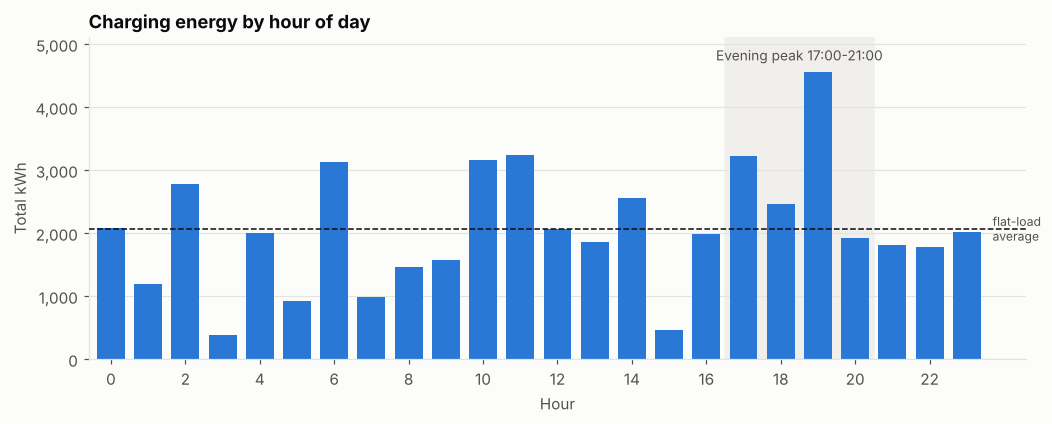

Peak window = 17% of the day but 24.5% of energy -> 1.47x its fair share
Busiest hour: 19:00 with 4,561 kWh across 9 events


In [4]:
hourly = df.groupby("hour")[KWH].agg(["sum", "count"]).reindex(range(24), fill_value=0)
fair_share = hourly["sum"].sum() / 24

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.axvspan(16.5, 20.5, color="#f0efec", zorder=0)
ax.text(18.5, hourly["sum"].max() * 1.04, "Evening peak 17:00-21:00", ha="center", color=INK_2, fontsize=9)
ax.bar(hourly.index, hourly["sum"], color=BLUE, width=0.75, zorder=2)
ax.axhline(fair_share, color=INK, linewidth=1, linestyle="--", zorder=3)
ax.text(23.6, fair_share, " flat-load\n average", va="center", color=INK_2, fontsize=8)
ax.set(title="Charging energy by hour of day", xlabel="Hour", ylabel="Total kWh", xlim=(-0.6, 24.6),
       ylim=(0, hourly["sum"].max() * 1.12))
ax.set_xticks(range(0, 24, 2))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", visible=False)
save(fig, "03_02_hourly_profile"); plt.show()

peak_share = df.loc[peak, KWH].sum() / df[KWH].sum()
print(f"Peak window = {4/24:.0%} of the day but {peak_share:.1%} of energy -> {peak_share / (4/24):.2f}x its fair share")
print(f"Busiest hour: {hourly['sum'].idxmax()}:00 with {hourly['sum'].max():,.0f} kWh across {hourly.loc[hourly['sum'].idxmax(), 'count']} events")

**Reading it**
- The 4-hour evening window holds about 1 in 4 kWh while covering 1 in 6 hours. That is ~1.5× its fair share.
- 19:00 is the single busiest hour (9 events, ~4,600 kWh). It is the hour that will set the network's peak load.
- Late-morning activity (10:00–11:00) forms a secondary shoulder, which is consistent with commercial and workplace charging.

Why it matters: substations are sized for peak demand, not average demand. The 19:00 hour is the one to model in the capacity assessment.

### 3b. Day of week and trend over time

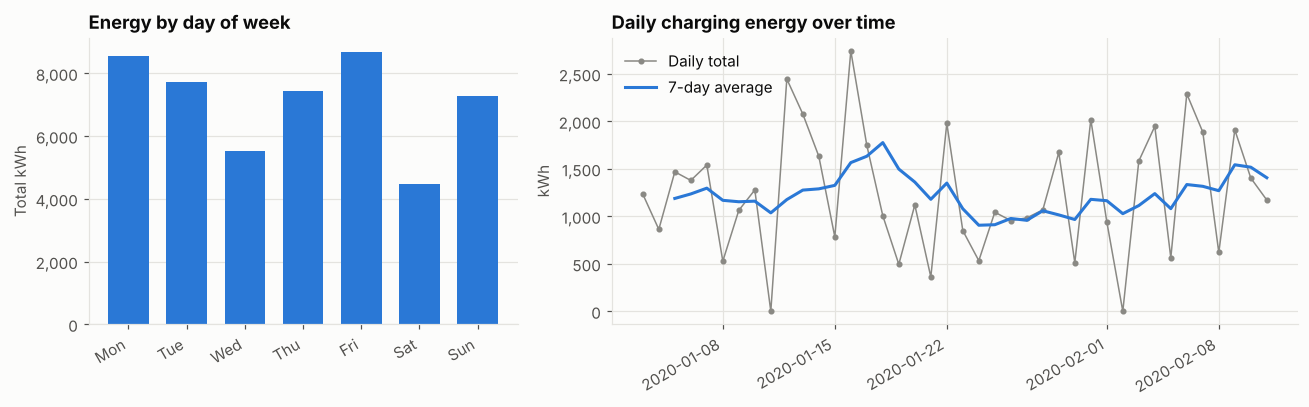

Weekday mean 520 kWh vs weekend 489 kWh | Kruskal-Wallis p = 0.13


In [5]:
DOW = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = df.groupby("day_of_week")[KWH].agg(["sum", "count", "mean"]).reindex(DOW)
daily = df.set_index("timestamp")[KWH].resample("D").sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})

ax = axes[0]
ax.bar([d[:3] for d in DOW], dow["sum"], color=BLUE, width=0.7)
ax.set(title="Energy by day of week", ylabel="Total kWh")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", visible=False)

ax = axes[1]
ax.plot(daily.index, daily.values, color=MUTED, linewidth=1, marker="o", markersize=3, label="Daily total")
ax.plot(daily.index, daily.rolling(7, min_periods=3).mean(), color=BLUE, linewidth=2, label="7-day average")
ax.set(title="Daily charging energy over time", ylabel="kWh")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend(loc="upper left")
fig.autofmt_xdate()
fig.tight_layout(); save(fig, "03_03_weekly_and_trend"); plt.show()

wk = df.groupby("is_weekend")[KWH]
print(f"Weekday mean {wk.mean()[False]:.0f} kWh vs weekend {wk.mean()[True]:.0f} kWh "
      f"| Kruskal-Wallis p = {stats.kruskal(*[g for _, g in wk]).pvalue:.2f}")

**Reading it**
- Weekday events average about 6% more energy than weekend events, but the difference is not statistically significant (p ≈ 0.13).
- Daily totals are volatile because the sample is small (0–5 events a day). The 7-day average shows no clear upward trend over these 38 days.

Why it matters: we cannot extract an adoption growth rate from this history. This confirms the Notebook 01 decision to use growth scenarios (2×, 3×, 5×) in the capacity assessment instead of a trend forecast.

## 4. Who and what drives consumption?
Two different questions are hidden in 'who drives demand':
- **Intensity:** does a given segment use more energy *per event*?
- **Volume:** does a segment account for more *total* energy, simply because it has more events?

In [6]:
SEGMENTS = {
    "geographical_area": "Area", "customer_type": "Customer type", "ev_type": "EV type",
    "charger_type": "Charger type", "charging_habit": "Charging habit",
}

rows = []
for col, label in SEGMENTS.items():
    groups = df.groupby(col)[KWH]
    p = stats.kruskal(*[g for _, g in groups]).pvalue
    for level, g in groups:
        rows.append({"segment": label, "level": level, "events": len(g), "total_kwh": g.sum(),
                     "share_of_kwh": g.sum() / df[KWH].sum(), "mean_kwh": g.mean(),
                     "ci95": 1.96 * g.std(ddof=1) / np.sqrt(len(g)), "kruskal_p": p})
seg = pd.DataFrame(rows)
seg.to_csv(REPORTS / "eda_segment_tests.csv", index=False)

(seg.groupby("segment", sort=False)
    .agg(levels=("level", "count"), spread_of_means_kwh=("mean_kwh", lambda m: m.max() - m.min()),
         kruskal_p=("kruskal_p", "first"))
    .assign(significant_at_5pct=lambda t: t["kruskal_p"] < 0.05))

,levels,spread_of_means_kwh,kruskal_p,significant_at_5pct
segment,,,,
Area,3,26.00,0.71,False
Customer type,3,33.64,0.22,False
EV type,3,23.88,0.40,False
Charger type,3,6.70,0.98,False
Charging habit,3,39.15,0.06,False


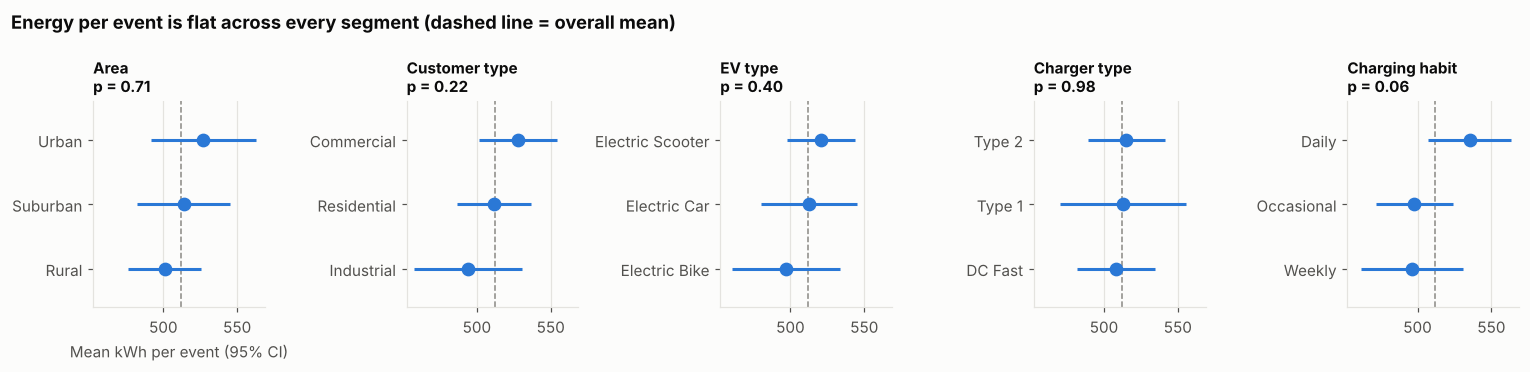

In [7]:
fig, axes = plt.subplots(1, len(SEGMENTS), figsize=(14, 3.4), sharex=True)
overall = df[KWH].mean()
for ax, (label, g) in zip(axes, seg.groupby("segment", sort=False)):
    g = g.sort_values("mean_kwh")
    y = np.arange(len(g))
    ax.axvline(overall, color=MUTED, linewidth=1, linestyle="--")
    ax.errorbar(g["mean_kwh"], y, xerr=g["ci95"], fmt="o", color=BLUE, ecolor=BLUE,
                elinewidth=2, capsize=0, markersize=8)
    ax.set_yticks(y, g["level"])
    ax.set_ylim(-0.6, len(g) - 0.4)
    ax.set_title(f"{label}\np = {g['kruskal_p'].iloc[0]:.2f}", fontsize=10)
    ax.grid(axis="y", visible=False)
axes[0].set_xlabel("Mean kWh per event (95% CI)")
fig.suptitle("Energy per event is flat across every segment (dashed line = overall mean)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "03_04_segment_intensity"); plt.show()

**Reading it: intensity**
- Every confidence interval overlaps the overall mean, and no segment differs significantly at the 5% level.
- `Charging habit` comes closest (p ≈ 0.06). Daily chargers use about 7% more per event than weekly or occasional chargers. It is a weak signal, worth tracking as more data arrives.
- Surprisingly, charger type makes no difference to energy (p ≈ 0.98). A DC fast charger delivers the same kWh as a Type 1 in this data, it just does it faster. That is exactly why charger type matters for capacity: the same energy over a shorter window means a higher power peak (kW). We will use this in Notebook 04.

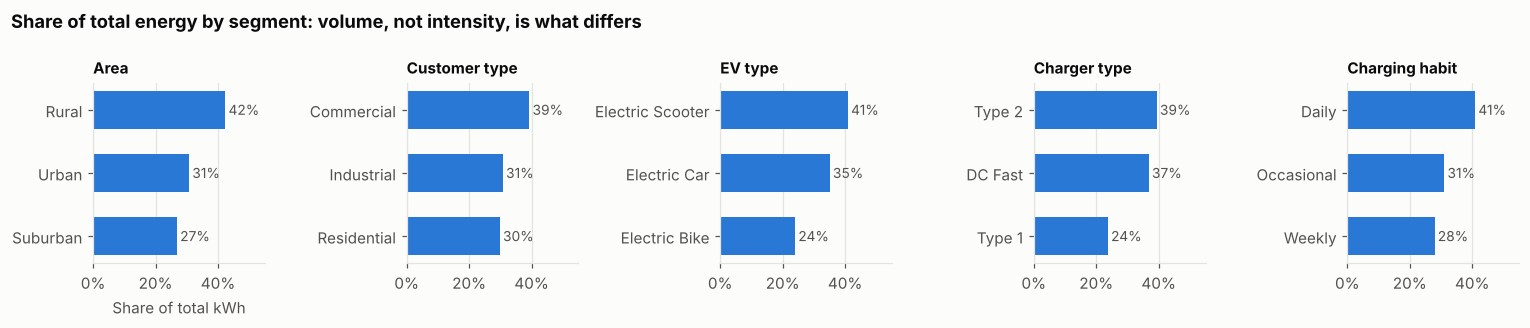

In [8]:
fig, axes = plt.subplots(1, len(SEGMENTS), figsize=(14, 3.0), sharex=True)
for ax, (label, g) in zip(axes, seg.groupby("segment", sort=False)):
    g = g.sort_values("total_kwh")
    ax.barh(g["level"], g["share_of_kwh"], color=BLUE, height=0.6)
    for yi, v in enumerate(g["share_of_kwh"]):
        ax.text(v + 0.01, yi, f"{v:.0%}", va="center", color=INK_2, fontsize=9)
    ax.set_title(label, fontsize=10)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set_xlim(0, 0.55)
    ax.grid(axis="y", visible=False)
axes[0].set_xlabel("Share of total kWh")
fig.suptitle("Share of total energy by segment: volume, not intensity, is what differs",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "03_05_segment_volume"); plt.show()

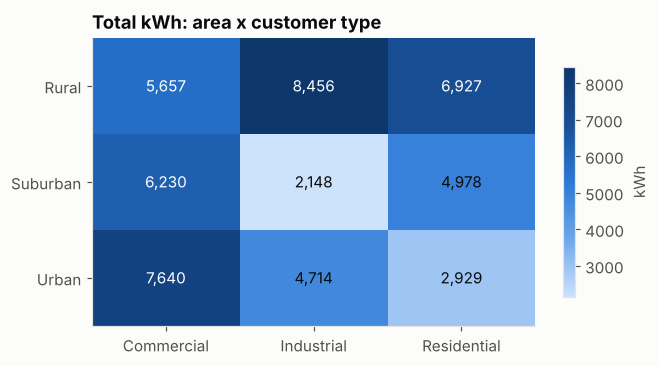

In [9]:
pivot = df.pivot_table(index="geographical_area", columns="customer_type", values=KWH, aggfunc="sum")
fig, ax = plt.subplots(figsize=(6.5, 3.4))
im = ax.imshow(pivot.values, cmap=SEQ_BLUE, aspect="auto")
ax.set_xticks(range(pivot.shape[1]), pivot.columns)
ax.set_yticks(range(pivot.shape[0]), pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        ax.text(j, i, f"{v:,.0f}", ha="center", va="center",
                color="white" if v > pivot.values.mean() else INK, fontsize=10)
ax.grid(False)
ax.set_title("Total kWh: area x customer type")
fig.colorbar(im, ax=ax, shrink=0.8, label="kWh")
save(fig, "03_06_area_customer_heatmap"); plt.show()

**Reading it: volume**
- Rural areas account for ~42% of all EV energy, mostly because they have the most charging events. The largest single cell is Rural × Industrial (~8,500 kWh).
- In Urban areas, commercial customers dominate. That fits workplace and retail charging, and it matches the late-morning shoulder in section 3a.
- **Insight for planning:** since energy per event is the same everywhere, *where load builds up is decided by how many charge points and sessions an area has*. Capacity planning should therefore follow the growth in charging sessions per substation, not customer segment labels.

## 5. Does weather move demand?

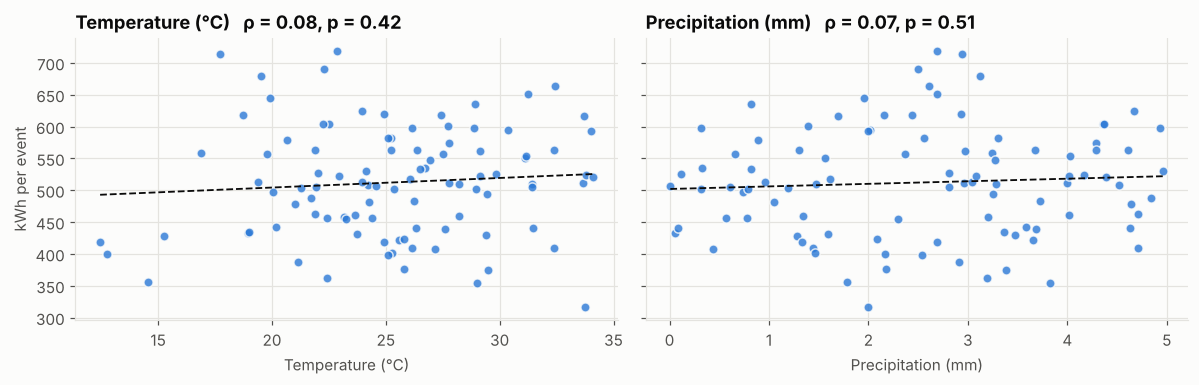

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, col, label in [(axes[0], "temperature_c", "Temperature (°C)"),
                       (axes[1], "precipitation_mm", "Precipitation (mm)")]:
    rho, p = stats.spearmanr(df[col], df[KWH])
    ax.scatter(df[col], df[KWH], s=36, color=BLUE, alpha=0.8, edgecolor=SURFACE, linewidth=1)
    slope, intercept = np.polyfit(df[col], df[KWH], 1)
    xs = np.linspace(df[col].min(), df[col].max(), 50)
    ax.plot(xs, slope * xs + intercept, color=INK, linewidth=1.2, linestyle="--")
    ax.set(title=f"{label}   ρ = {rho:.2f}, p = {p:.2f}", xlabel=label)
axes[0].set_ylabel("kWh per event")
fig.tight_layout(); save(fig, "03_07_weather"); plt.show()

**Reading it**
- Correlations with temperature (ρ ≈ 0.08) and precipitation (ρ ≈ 0.07) are negligible and not significant.
- The data covers only Jan–Feb with mostly mild-to-warm readings, so we cannot rule out a weather effect in real extremes. For example, cold reduces battery efficiency and raises charging energy in winter.

Why it matters: weather will not be a driver in the capacity model. In the report we will recommend collecting a full year of weather and load data to test seasonal effects properly.

## 6. Correlation overview
Spearman rank correlation is robust to the skew in `kwh_per_ev` and to outliers.

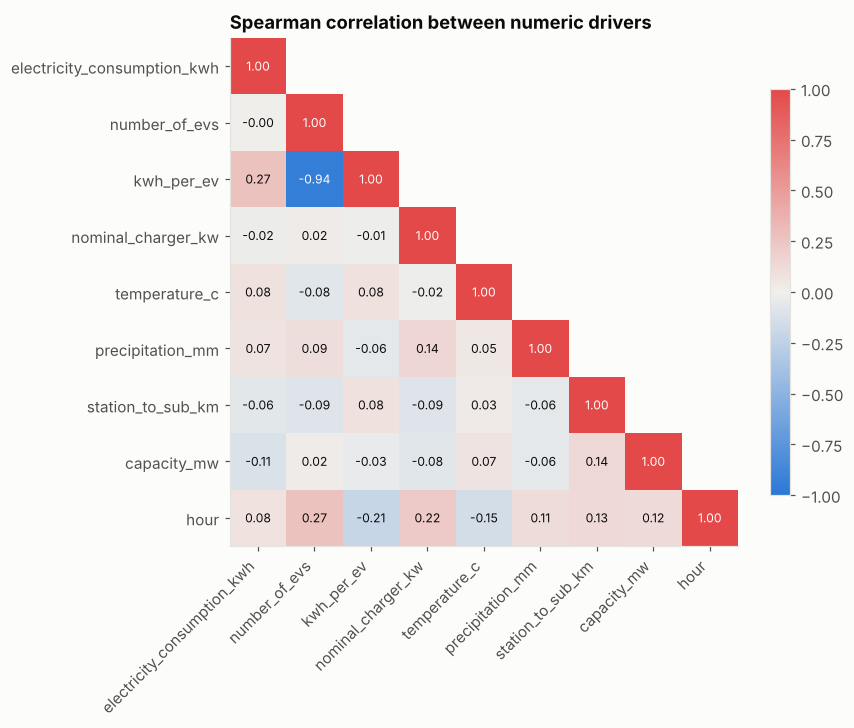

In [11]:
NUM = ["electricity_consumption_kwh", "number_of_evs", "kwh_per_ev", "nominal_charger_kw",
       "temperature_c", "precipitation_mm", "station_to_sub_km", "capacity_mw", "hour"]
corr = df[NUM].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(np.ma.masked_where(mask, corr), cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM)), NUM, rotation=45, ha="right")
ax.set_yticks(range(len(NUM)), NUM)
for i in range(len(NUM)):
    for j in range(i + 1):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else INK)
ax.grid(False)
ax.set_title("Spearman correlation between numeric drivers")
fig.colorbar(im, ax=ax, shrink=0.8)
save(fig, "03_08_correlation"); plt.show()

**Reading it**
- The only strong relationships are structural: `kwh_per_ev` is derived from `number_of_evs`, so they correlate negatively by construction.
- One relationship is worth carrying forward. Later hours bring more EVs per site (ρ ≈ 0.27) and faster chargers (ρ ≈ 0.22). Both are weak but significant at n = 97. The energy is unchanged, but the evening peak is drawn through higher-power equipment, which raises peak kW exactly when the network is busiest.
- Nothing in the data predicts energy per event. Fleet size, charger rating, weather, distance, and hour all sit near zero.

Implication: a regression model for kWh per event would have almost no explanatory power. The right lever is aggregation: how many events land on each substation, and when. That leads directly into section 7 and the capacity assessment.

## 7. Where is load concentrated? (substation view)

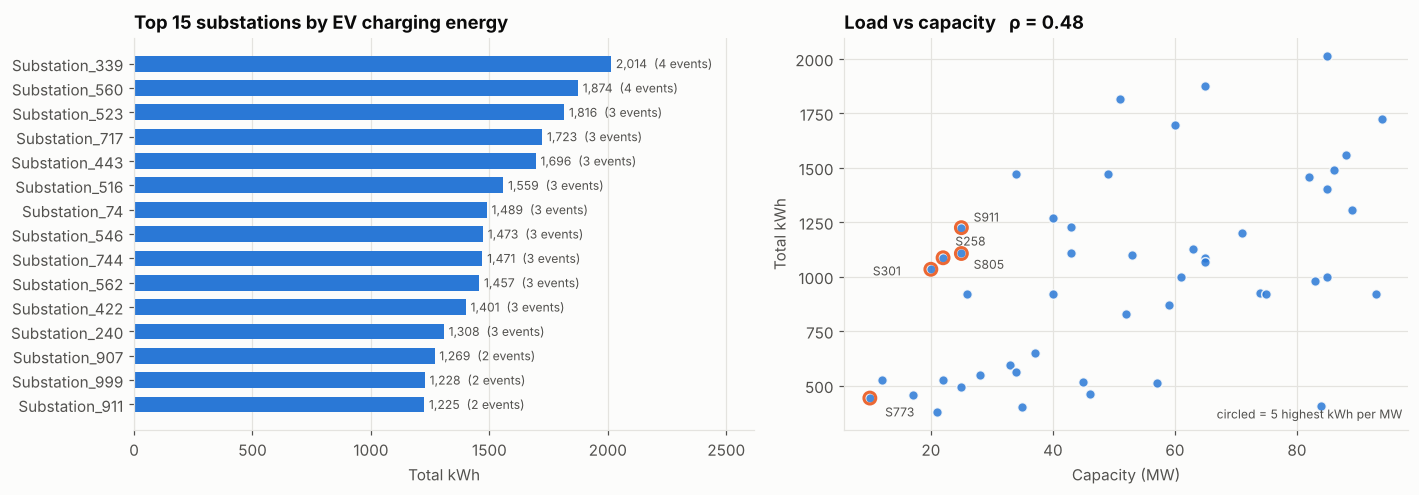

,total_kwh,events,capacity_mw,kwh_per_mw,area
substation_id,,,,,
Substation_301,"1,033.85",2,20,51.69,Rural
Substation_258,"1,086.59",2,22,49.39,Suburban
Substation_911,"1,224.80",2,25,48.99,Suburban
Substation_773,442.63,1,10,44.26,Rural
Substation_805,"1,106.26",2,25,44.25,Rural


In [12]:
subs = (df.groupby("substation_id")
          .agg(total_kwh=(KWH, "sum"), events=(KWH, "size"), peak_events=("is_peak_hour", "sum"),
               capacity_mw=("capacity_mw", "first"), area=("geographical_area", lambda s: s.mode()[0]))
          .sort_values("total_kwh", ascending=False))
subs["kwh_per_mw"] = subs["total_kwh"] / subs["capacity_mw"]

top = subs.head(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})

ax = axes[0]
ax.barh(top.index, top["total_kwh"], color=BLUE, height=0.65)
for yi, (v, n) in enumerate(zip(top["total_kwh"], top["events"])):
    ax.text(v + 20, yi, f"{v:,.0f}  ({n} events)", va="center", color=INK_2, fontsize=8)
ax.set(title="Top 15 substations by EV charging energy", xlabel="Total kWh", xlim=(0, top["total_kwh"].max() * 1.3))
ax.grid(axis="y", visible=False)

ax = axes[1]
rho, p = stats.spearmanr(subs["capacity_mw"], subs["total_kwh"])
ax.scatter(subs["capacity_mw"], subs["total_kwh"], s=40, color=BLUE, alpha=0.85, edgecolor=SURFACE, linewidth=1)
hot = subs.nlargest(5, "kwh_per_mw")
ax.scatter(hot["capacity_mw"], hot["total_kwh"], s=60, facecolor="none", edgecolor=ORANGE, linewidth=2)
# Staggered label offsets so neighbouring points do not collide
offsets = [(10, -12), (-38, -4), (8, 8), (8, -10), (8, 4)]
for (sid, r), off in zip(hot.sort_values("total_kwh").iterrows(), offsets):
    ax.annotate(sid.replace("Substation_", "S"), (r["capacity_mw"], r["total_kwh"]),
                xytext=off, textcoords="offset points", fontsize=8, color=INK_2)
ax.set(title=f"Load vs capacity   ρ = {rho:.2f}", xlabel="Capacity (MW)", ylabel="Total kWh")
ax.text(0.99, 0.03, "circled = 5 highest kWh per MW", transform=ax.transAxes, ha="right", fontsize=8, color=INK_2)

fig.tight_layout(); save(fig, "03_09_substation_load"); plt.show()
hot[["total_kwh", "events", "capacity_mw", "kwh_per_mw", "area"]]

**Reading it**
- Load is spread thinly: the busiest substation (Substation_339) carries only 4 events, and most substations see 1–3.
- Substation load and capacity are positively correlated (ρ ≈ 0.48), so larger substations tend to serve more charging. That is reassuring, but it is not the whole story.
- The circled points show substations carrying the most energy relative to their capacity. Small substations with above-average load are the early bottleneck candidates. Notebook 04 will turn this kWh-per-MW proxy into a proper peak utilisation % using the charger-power assumptions.

## 8. Key insights

| # | Insight | Evidence | So what for PowerCharge |
|---|---|---|---|
| 1 | Load concentrates in the evening. | 17:00–21:00 = 17% of hours, ~25% of energy (1.5× fair share); 19:00 is the busiest hour | Size and stress-test the network on the 19:00 peak. Time-of-use tariffs could shift load. |
| 2 | Energy per event is the same for every segment. | No significant Kruskal–Wallis result across area, customer type, EV type, charger type, or habit | Plan on session counts per substation, not on customer labels |
| 3 | Charger type changes power, not energy. | DC Fast ≈ Type 1 in kWh (p ≈ 0.98) | Fast chargers deliver the same energy in less time, which means higher peak kW. Model this explicitly. |
| 4 | Rural areas carry the most volume. | ~42% of energy; Rural × Industrial is the largest cell | Rural feeders tend to be longer and weaker, so check them first for bottlenecks |
| 5 | Weather has no measurable effect in this window. | ρ < 0.1, not significant | Exclude weather from the model and flag seasonality as a data gap |
| 6 | No trend in 38 days. | Flat 7-day average | Use growth scenarios (2×/3×/5×) instead of a forecast |
| 7 | Small substations with high load are the early-warning list. | Top-5 kWh/MW substations circled in section 7 | Input to Notebook 04 utilisation and Notebook 05 risk scoring |

**Next:** `04_capacity_assessment.ipynb`: convert energy into peak power (MW), compare it with each substation's capacity, and stress-test utilisation under EV growth scenarios and different charger-power assumptions.